In [ ]:
from collections import Counter
from pathlib import Path
import kagglehub
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

# Download Kaggle Flowers Recognition dataset
download_path = Path(kagglehub.dataset_download("alxmamaev/flowers-recognition"))
DATASET_DIR = download_path / "flowers" if (download_path / "flowers").exists() else download_path

IMG_SIZE = (64, 64)
BATCH_SIZE = 32
SEED = 42

class_names = sorted(
    p.name for p in DATASET_DIR.iterdir() if p.is_dir()
)
class_to_idx = {name: i for i, name in enumerate(class_names)}

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

paths, labels = [], []

for class_name in class_names:
    for path in (DATASET_DIR / class_name).rglob("*"):
        if path.suffix.lower() in extensions:
            paths.append(str(path))
            labels.append(class_to_idx[class_name])

class_counts = Counter(labels)

print("\nImages per class:")
for class_name, class_idx in class_to_idx.items():
    print(f"{class_name:30s}: {class_counts[class_idx]}")

# 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    paths, labels,
    test_size=0.30,
    stratify=labels,
    random_state=SEED
)

# Split the remaining 30% into 15% validation and 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED
)

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = image / 255.0
    return image, label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

print(f"Training:   {len(X_train)} ({len(X_train)/len(paths):.1%})")
print(f"Validation: {len(X_val)} ({len(X_val)/len(paths):.1%})")
print(f"Testing:    {len(X_test)} ({len(X_test)/len(paths):.1%})")
print("Classes:", class_to_idx)



ModuleNotFoundError: No module named 'kagglehub'

Training:   3021 (70.0%)
Validation: 648 (15.0%)
Testing:    648 (15.0%)
Classes: {'daisy': 0, 'dandelion': 1, 'rose': 2, 'sunflower': 3, 'tulip': 4}


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 2, 2, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,253,653 (23.86 MB)

 Trainable params: 331,781 (1.27 MB)

 Non-trainable params: 5,921,872 (22.59 MB)

Epoch 1/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.4533 - loss: 1.7169
Epoch 1: val_accuracy improved from None to 0.74074, saving model to best_efficientnetv2b0.keras

Epoch 1: finished saving model to best_efficientnetv2b0.keras
95/95 ━━━━━━━━━━━━━━━━━━━━ 25s 100ms/step - accuracy: 0.5528 - loss: 1.3910 - val_accuracy: 0.7407 - val_loss: 0.8291 - learning_rate: 0.0010
Epoch 2/20
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.6505 - loss: 1.0554
Epoch 2: val_accuracy improved from 0.74074 to 0.77160, saving model to best_efficientnetv2b0.keras

Epoch 2: finished saving model to best_efficientnetv2b0.keras
95/95 ━━━━━━━━━━━━━━━━━━━━ 6s 63ms/step - accuracy: 0.6647 - loss: 1.0410 - val_accuracy: 0.7716 - val_loss: 0.7177 - learning_rate: 0.0010
Epoch 3/20
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.7122 - loss: 0.9059
Epoch 3: val_accuracy did not improve from 0.77160
95/95 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - accuracy: 0.7167 - loss: 0.8882 - val_accuracy:

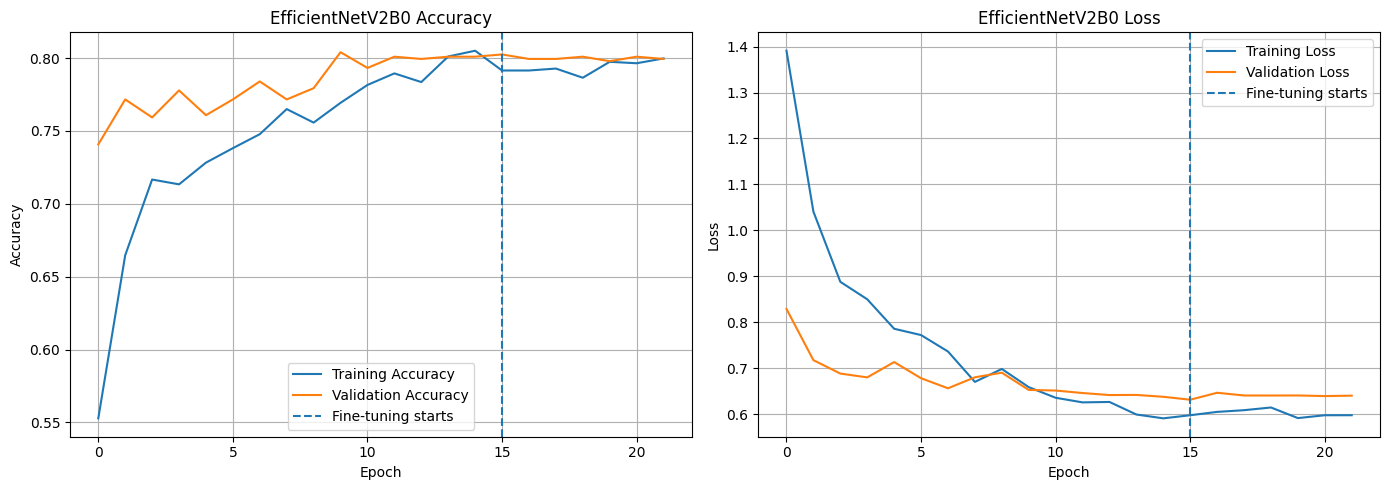

21/21 ━━━━━━━━━━━━━━━━━━━━ 6s 171ms/step
              precision    recall  f1-score   support

       daisy     0.7131    0.7565    0.7342       115
   dandelion     0.8462    0.8354    0.8408       158
        rose     0.7544    0.7350    0.7446       117
   sunflower     0.8557    0.7545    0.8019       110
       tulip     0.7421    0.7973    0.7687       148

    accuracy                         0.7809       648
   macro avg     0.7823    0.7758    0.7780       648
weighted avg     0.7838    0.7809    0.7814       648



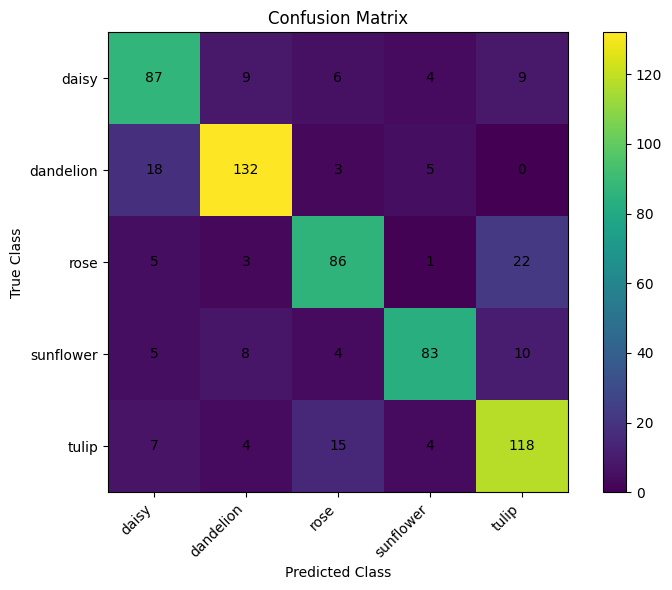

In [2]:
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = image
    return image, label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

print(f"Training:   {len(X_train)} ({len(X_train)/len(paths):.1%})")
print(f"Validation: {len(X_val)} ({len(X_val)/len(paths):.1%})")
print(f"Testing:    {len(X_test)} ({len(X_test)/len(paths):.1%})")
print("Classes:", class_to_idx)
# ============================================================
# EfficientNetV2B0 - Transfer Learning
# ============================================================

num_classes = len(class_names)

# Data augmentation
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.10)
], name="data_augmentation")


# Load pretrained EfficientNetV2B0
base_model = tf.keras.applications.EfficientNetV2B0(
    include_top=False,
    weights="imagenet",
    input_shape=(64, 64, 3),
    include_preprocessing=True
)

# Freeze pretrained layers initially
base_model.trainable = False


# Build model
inputs = keras.Input(shape=(64, 64, 3))

x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.35)(x)

x = layers.Dense(
    256,
    activation="relu",
    kernel_regularizer=keras.regularizers.l2(1e-4)
)(x)

x = layers.Dropout(0.25)(x)

outputs = layers.Dense(
    num_classes,
    activation="softmax"
)(x)

model = keras.Model(inputs, outputs)

model.summary()


# ============================================================
# Compile model
# ============================================================

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# ============================================================
# Callbacks
# ============================================================

callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_efficientnetv2b0.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=6,
        restore_best_weights=True,
        mode="max",
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]


# ============================================================
# Phase 1: Train classification head
# ============================================================

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)


# ============================================================
# Phase 2: Fine-tune the backbone
# ============================================================

base_model.trainable = True

# Unfreeze the final 30% of layers
fine_tune_at = int(len(base_model.layers) * 0.70)

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)


# ============================================================
# Evaluate best saved model on test set
# ============================================================

best_model = keras.models.load_model(
    "best_efficientnetv2b0.keras"
)

test_loss, test_accuracy = best_model.evaluate(test_ds)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4%}")


# ============================================================
# Plot accuracy and loss
# ============================================================

train_acc = (
    history_head.history["accuracy"]
    + history_fine.history["accuracy"]
)

val_acc = (
    history_head.history["val_accuracy"]
    + history_fine.history["val_accuracy"]
)

train_loss = (
    history_head.history["loss"]
    + history_fine.history["loss"]
)

val_loss = (
    history_head.history["val_loss"]
    + history_fine.history["val_loss"]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(train_acc, label="Training Accuracy")
axes[0].plot(val_acc, label="Validation Accuracy")
axes[0].axvline(
    len(history_head.history["accuracy"]) - 1,
    linestyle="--",
    label="Fine-tuning starts"
)
axes[0].set_title("EfficientNetV2B0 Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(train_loss, label="Training Loss")
axes[1].plot(val_loss, label="Validation Loss")
axes[1].axvline(
    len(history_head.history["loss"]) - 1,
    linestyle="--",
    label="Fine-tuning starts"
)
axes[1].set_title("EfficientNetV2B0 Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# Classification report
# ============================================================

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = best_model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    digits=4,
    zero_division=0
))


# ============================================================
# Confusion matrix
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(num_classes))
)

plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix")
plt.colorbar()

plt.xticks(
    np.arange(num_classes),
    class_names,
    rotation=45,
    ha="right"
)
plt.yticks(np.arange(num_classes), class_names)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

for i in range(num_classes):
    for j in range(num_classes):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.tight_layout()
plt.show()


# Save final best model
best_model.save("efficientnetv2b0_flowers_final.keras")

In [3]:
# Load the best model from your previous training
model = keras.models.load_model(
    "best_efficientnetv2b0.keras"
)

# Find the backbone
base_model = model.get_layer("efficientnetv2-b0")

# Unfreeze all backbone layers
base_model.trainable = True

# Keep batch normalization frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Recompile with a very low learning rate
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-6),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks_more_fine = [
    keras.callbacks.ModelCheckpoint(
        "best_efficientnetv2b0_v2.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=6,
        restore_best_weights=True,
        mode="max"
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-8,
        verbose=1
    )
]

history_more_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks_more_fine
)

Epoch 1/20
95/95 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.7986 - loss: 0.5891
Epoch 1: val_accuracy improved from None to 0.80093, saving model to best_efficientnetv2b0_v2.keras

Epoch 1: finished saving model to best_efficientnetv2b0_v2.keras
95/95 ━━━━━━━━━━━━━━━━━━━━ 35s 127ms/step - accuracy: 0.7951 - loss: 0.5952 - val_accuracy: 0.8009 - val_loss: 0.6526 - learning_rate: 1.0000e-06
Epoch 2/20
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.8008 - loss: 0.5852
Epoch 2: val_accuracy improved from 0.80093 to 0.80247, saving model to best_efficientnetv2b0_v2.keras

Epoch 2: finished saving model to best_efficientnetv2b0_v2.keras
95/95 ━━━━━━━━━━━━━━━━━━━━ 9s 99ms/step - accuracy: 0.8024 - loss: 0.5880 - val_accuracy: 0.8025 - val_loss: 0.6481 - learning_rate: 1.0000e-06
Epoch 3/20
94/95 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.7910 - loss: 0.6242
Epoch 3: val_accuracy did not improve from 0.80247
95/95 ━━━━━━━━━━━━━━━━━━━━ 8s 78ms/step - accuracy: 0.7928 - loss: 0.

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_5 (Sequential)       │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 64, 64, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_13 (Activation)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_14 (Activation)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │       131,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_15 (Activation)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 155,429 (607.14 KB)

 Trainable params: 155,141 (606.02 KB)

 Non-trainable params: 288 (1.12 KB)

Epoch 1/50
95/95 - 8s - 87ms/step - accuracy: 0.3459 - loss: 1.6816 - val_accuracy: 0.2438 - val_loss: 1.7328
Epoch 2/50
95/95 - 4s - 45ms/step - accuracy: 0.4409 - loss: 1.4134 - val_accuracy: 0.2438 - val_loss: 1.7622
Epoch 3/50
95/95 - 4s - 46ms/step - accuracy: 0.4724 - loss: 1.3382 - val_accuracy: 0.3302 - val_loss: 1.4333
Epoch 4/50
95/95 - 4s - 45ms/step - accuracy: 0.4839 - loss: 1.2834 - val_accuracy: 0.5262 - val_loss: 1.2013
Epoch 5/50
95/95 - 5s - 52ms/step - accuracy: 0.5015 - loss: 1.2637 - val_accuracy: 0.5648 - val_loss: 1.1507
Epoch 6/50
95/95 - 5s - 53ms/step - accuracy: 0.5184 - loss: 1.2222 - val_accuracy: 0.5679 - val_loss: 1.1248
Epoch 7/50
95/95 - 5s - 49ms/step - accuracy: 0.5359 - loss: 1.1691 - val_accuracy: 0.5293 - val_loss: 1.1778
Epoch 8/50
95/95 - 4s - 44ms/step - accuracy: 0.5422 - loss: 1.1580 - val_accuracy: 0.5293 - val_loss: 1.1960
Epoch 9/50
95/95 - 4s - 47ms/step - accuracy: 0.5405 - loss: 1.1628 - val_accuracy: 0.5478 - val_loss: 1.1460
Epoch 10/5

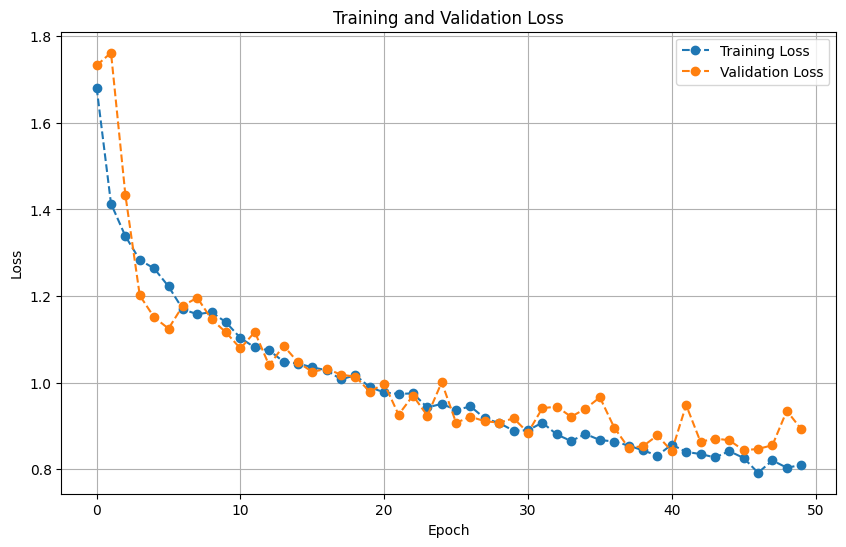

In [8]:
# Define the CNN model
num_classes = len(class_names)

# Data Augmentation Pipeline
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1), # Rotate by up to 10%
    layers.RandomZoom(0.1),      # Zoom by up to 10%
])


model = keras.Sequential([
    layers.Input(shape=(64, 64, 3)),
    data_augmentation,

    # Block 1
    layers.Conv2D(16, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(32, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(64, (3, 3), padding='same'),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    # Classifier Head
    layers.Flatten(),
    layers.Dense(32),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(0.5), # Dropout for regularization
    layers.Dense(num_classes, activation='softmax')


])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# Train using the existing training and validation datasets
history = model.fit(
    train_ds,
    epochs=50,
    validation_data=val_ds,
    verbose=2
)

# Evaluate on the test set after training
test_loss, test_accuracy = model.evaluate(test_ds, verbose=2)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Plot training and validation loss
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training Loss', linestyle='--', marker='o')
plt.plot(history.history['val_loss'], label='Validation Loss', linestyle='--', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [13]:
from collections import Counter
from pathlib import Path
import kagglehub
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

# 1. Download Intel Image Classification dataset
download_path = Path(kagglehub.dataset_download("puneet6060/intel-image-classification"))

# Path to the training folder containing the 6 classes
DATASET_DIR = download_path / "seg_train" / "seg_train" if (download_path / "seg_train" / "seg_train").exists() else download_path / "seg_train"

# Intel images are natively 150x150
IMG_SIZE = (64, 64)
BATCH_SIZE = 32
SEED = 42

class_names = sorted(
    p.name for p in DATASET_DIR.iterdir() if p.is_dir() and not p.name.startswith(".")
)
class_to_idx = {name: i for i, name in enumerate(class_names)}

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

paths, labels = [], []

for class_name in class_names:
    for path in (DATASET_DIR / class_name).rglob("*"):
        if path.suffix.lower() in extensions:
            paths.append(str(path))
            labels.append(class_to_idx[class_name])

class_counts = Counter(labels)

print("\nImages per class:")
for class_name, class_idx in class_to_idx.items():
    print(f"{class_name:30s}: {class_counts[class_idx]}")

# 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    paths, labels,
    test_size=0.30,
    stratify=labels,
    random_state=SEED
)

# Split the remaining 30% into 15% validation and 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED
)

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = image / 255.0
    return image, label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).cache().prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

print(f"\nTraining:   {len(X_train)} ({len(X_train)/len(paths):.1%})")
print(f"Validation: {len(X_val)} ({len(X_val)/len(paths):.1%})")
print(f"Testing:    {len(X_test)} ({len(X_test)/len(paths):.1%})")
print("Classes:", class_to_idx)

Using Colab cache for faster access to the 'intel-image-classification' dataset.

Images per class:
buildings                     : 2191
forest                        : 2271
glacier                       : 2404
mountain                      : 2512
sea                           : 2274
street                        : 2382

Training:   9823 (70.0%)
Validation: 2105 (15.0%)
Testing:    2106 (15.0%)
Classes: {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


In [5]:
from collections import Counter
from pathlib import Path
import urllib.request
import zipfile
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

# Download Waste dataset (TrashNet - direct download, no login needed)
zip_url = "https://huggingface.co/datasets/garythung/trashnet/resolve/main/dataset-resized.zip"
zip_path = Path("trashnet.zip")
extract_dir = Path("waste_dataset")

if not extract_dir.exists():
    urllib.request.urlretrieve(zip_url, zip_path)
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_dir)

DATASET_DIR = extract_dir / "dataset-resized"

IMG_SIZE = (64, 64)
BATCH_SIZE = 32
SEED = 42

class_names = sorted(
    p.name for p in DATASET_DIR.iterdir() if p.is_dir() and not p.name.startswith(".")
)
class_to_idx = {name: i for i, name in enumerate(class_names)}

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

paths, labels = [], []

for class_name in class_names:
    for path in (DATASET_DIR / class_name).rglob("*"):
        if path.suffix.lower() in extensions:
            paths.append(str(path))
            labels.append(class_to_idx[class_name])

class_counts = Counter(labels)

print("\nImages per class:")
for class_name, class_idx in class_to_idx.items():
    print(f"{class_name:30s}: {class_counts[class_idx]}")

# 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    paths, labels,
    test_size=0.30,
    stratify=labels,
    random_state=SEED
)

# Split the remaining 30% into 15% validation and 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED
)

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = image / 255.0
    return image, label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

print(f"Training:   {len(X_train)} ({len(X_train)/len(paths):.1%})")
print(f"Validation: {len(X_val)} ({len(X_val)/len(paths):.1%})")
print(f"Testing:    {len(X_test)} ({len(X_test)/len(paths):.1%})")
print("Classes:", class_to_idx)


Images per class:
cardboard                     : 403
glass                         : 501
metal                         : 410
paper                         : 594
plastic                       : 482
trash                         : 137
Training:   1768 (70.0%)
Validation: 379 (15.0%)
Testing:    380 (15.0%)
Classes: {'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,758 (401.40 KB)

 Trainable params: 102,182 (399.15 KB)

 Non-trainable params: 576 (2.25 KB)

Epoch 1/50
56/56 - 8s - 149ms/step - accuracy: 0.3292 - loss: 1.7122 - val_accuracy: 0.1609 - val_loss: 1.8460 - learning_rate: 1.0000e-04
Epoch 2/50
56/56 - 2s - 32ms/step - accuracy: 0.4695 - loss: 1.4230 - val_accuracy: 0.1609 - val_loss: 1.8680 - learning_rate: 1.0000e-04
Epoch 3/50
56/56 - 2s - 44ms/step - accuracy: 0.5023 - loss: 1.3461 - val_accuracy: 0.2032 - val_loss: 1.8437 - learning_rate: 1.0000e-04
Epoch 4/50
56/56 - 3s - 46ms/step - accuracy: 0.5170 - loss: 1.3085 - val_accuracy: 0.3245 - val_loss: 1.7993 - learning_rate: 1.0000e-04
Epoch 5/50
56/56 - 2s - 31ms/step - accuracy: 0.5577 - loss: 1.2162 - val_accuracy: 0.2902 - val_loss: 1.7915 - learning_rate: 1.0000e-04
Epoch 6/50
56/56 - 3s - 47ms/step - accuracy: 0.5594 - loss: 1.1873 - val_accuracy: 0.3008 - val_loss: 1.7539 - learning_rate: 1.0000e-04
Epoch 7/50
56/56 - 2s - 43ms/step - accuracy: 0.5735 - loss: 1.1739 - val_accuracy: 0.4090 - val_loss: 1.5888 - learning_rate: 1.0000e-04
Epoch 8/50
56/56 - 3s - 46ms/step

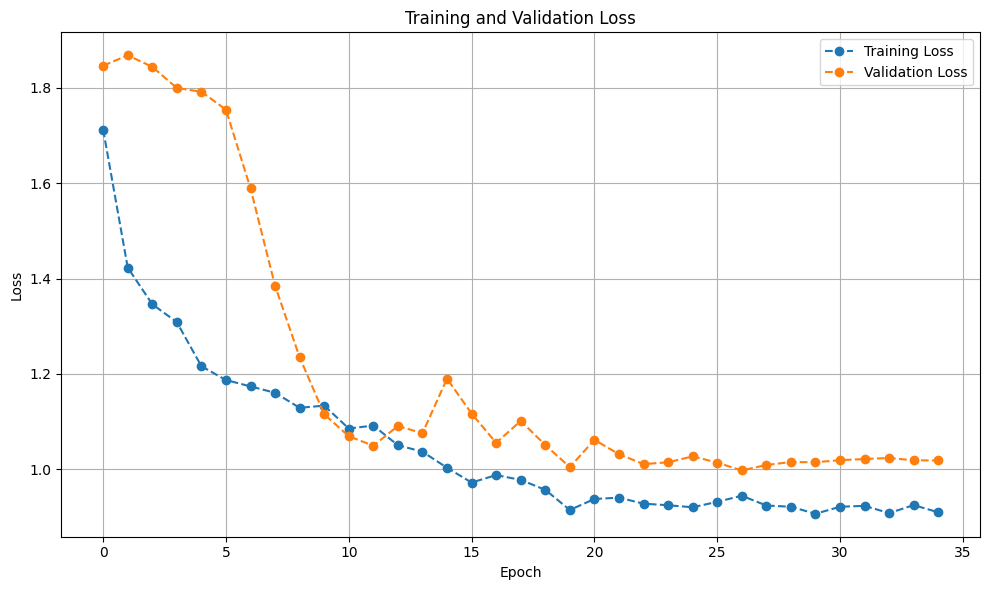

In [4]:
# Number of classes
num_classes = len(class_names)

# Data Augmentation Pipeline
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

# Define the CNN model
model = keras.Sequential([
    layers.Input(shape=(64, 64, 3)),

    data_augmentation,

    # Block 1
    layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Classifier Head
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.4),

    layers.Dense(num_classes, activation="softmax")
])

# Compile the model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# Callbacks
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

# Train the model
history = model.fit(
    train_ds,
    epochs=50,
    validation_data=val_ds,
    callbacks=[early_stopping, reduce_lr],
    verbose=2
)

# Evaluate on the test set after training
test_loss, test_accuracy = model.evaluate(test_ds, verbose=2)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Plot training and validation loss
plt.figure(figsize=(10, 6))
plt.plot(
    history.history["loss"],
    label="Training Loss",
    linestyle="--",
    marker="o"
)
plt.plot(
    history.history["val_loss"],
    label="Validation Loss",
    linestyle="--",
    marker="o"
)
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
